# 📘 Explained copy — 05 Equity returns: can ML pick stocks? (Module 5)

Study copy of `notebooks/05_equity_returns.ipynb`. Original cells unchanged (with outputs); above each is an
**Explanation**: *what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** 15 stocks, daily 2021-01 → 2026-08. We build monthly features known at each month-end
(momentum, reversal, volatility, beta, volume trend, distance to high), target = **next-month return minus the
15-stock average** (relative performance), and run a strict **walk-forward** (expanding window, refit monthly, first
forecast after 24 months → 38 out-of-sample months). Models: Ridge, RF, GB, vs Momentum and a zero forecast.
**Ridge has the best rank IC (0.056) but t = 1.2 < 2 → not statistically reliable.** Top-5 portfolios do not beat
equal-weight of all 15 (Sharpe 1.32, best) — stocks are almost uncorrelated (ρ ≈ 0.004), so diversification dominates.
Conclusion: **diversify first; use ML at most as a tilt** (tested in notebook 06).

**Key numbers:** Ridge IC 0.056 (t 1.23, positive 57% of months) · OOS R² ≈ 0 · EW Sharpe 1.32 · GB top-5 20.4% p.a.,
Sharpe 1.03 · all p-values > 0.4 · turnover ~68%/month.

> ### 📘 Explanation — cell 0
> **What it is.** Business question, chain (prices → monthly features → forecast → rank → top stocks → realised result)
> and the four design decisions.
>
> **Why each decision.**
> - **Monthly rebalance:** daily trading would let costs eat any small edge.
> - **Excess return target** (vs 15-stock average): removes the common market move, so the model learns *which* stock
>   wins (cross-sectional selection), the actual decision.
> - **Walk-forward:** train only on earlier months → exactly what could be done in real time; random K-fold on time
>   series would leak future information.
> - **No look-ahead:** features end on the rebalance day; target starts the day after.

# 05. Equity markets: can ML pick stocks with superior future returns? (Module 5)

**Business question (investment committee).** Can ML identify which of our 15 stocks will do better next month?

**Chain.** Daily prices → monthly features known at each rebalance date → ML forecast of next-month return
→ rank the stocks → buy the top-ranked ones → measure the realised result (rank IC, hit rate, portfolio return).
Notebook 06 then turns these forecasts into full portfolios (equal-weight, Markowitz, ML) and backtests them.

**Brief tasks covered.**
1. Predict future returns with several models.
2. For every rebalance date: predict, rank, select the top stocks, build a portfolio.

**Design decisions (and why).**
- **Monthly rebalance** on the last trading day of each month. Daily rebalancing would drown any edge in costs.
- **Target = next-month return minus the average of all 15 stocks that month** ("excess" return). The question is
  *which* stocks beat the others, not where the whole market goes, so the model learns relative performance.
- **Walk-forward validation**: at each month-end the model is trained **only on earlier months** and predicts the next
  month. Nothing is shuffled. This mimics exactly what the desk could have done in real time.
- **No look-ahead**: every feature uses data up to and including the rebalance day; the target starts the day after.

> ### 📘 Explanation — cell 1
> **What it does.** Loads helpers and sets output folders for Module 5.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('05')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_05_Equity_Returns/ and figures/Module_05_Equity_Returns/


> ### 📘 Explanation — cell 2
> **What it does.** Imports Ridge (L2-regularised linear regression), RF regressor, HistGB regressor, scaler, pipeline, scipy.stats (t-tests, Spearman).
>
> **Why Ridge.** With noisy returns and correlated features, OLS coefficients would be unstable; Ridge shrinks them toward
> zero, trading a little bias for much lower variance.

In [2]:
from sklearn.linear_model import Ridge                                     # model 1: regularised linear regression
from sklearn.ensemble import RandomForestRegressor                         # model 2: bagged trees
from sklearn.ensemble import HistGradientBoostingRegressor                 # model 3: boosted trees
from sklearn.preprocessing import StandardScaler                           # scaling for Ridge
from sklearn.pipeline import make_pipeline                                 # prep + model in one object
from scipy import stats                                                    # t-tests and rank correlation
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

> ### 📘 Explanation — cell 3
> **What it does.** Assumptions: risk-free 7%, transaction cost **10 bps** per unit traded, hold **top 5** of 15 (top third),
> first forecast after **24 months** of training history.
>
> **Why.** Costs must be in any backtest (turnover kills edges); 24 months gives the models enough history to fit.

In [3]:
RF_ANNUAL = ASSUMPTIONS['RISK_FREE']          # 7% risk-free rate (for Sharpe ratios)
TC = 0.0010                                   # transaction cost: 10 bps (0.10%) per unit of value traded (assumption)
TOP_N = 5                                     # number of stocks held by the ML portfolio (top third of 15)
MIN_TRAIN_MONTHS = 24                         # first forecast only after 2 years of training history

> ### 📘 Explanation — cell 4
> **What it does.** Loads daily market data, sorts by ticker and date. **Output:** (21,855, 15), 15 tickers, 2021-01-29 → 2026-08-31.

In [4]:
mkt = load('market', parse_dates=['Date'])                  # daily prices for 15 stocks
mkt = mkt.sort_values(['Ticker', 'Date']).reset_index(drop=True)   # time order within each stock
print(mkt.shape, '|', mkt.Ticker.nunique(), 'tickers |', mkt.Date.min().date(), 'to', mkt.Date.max().date())
mkt.head(3)

(21855, 15) | 15 tickers | 2021-01-29 to 2026-08-31


,Ticker,Date,Open,High,Low,Close,Volume,Sector,Market_Return,GDP_Growth,Interest_Rate,VIX,Return,Momentum_20D,Volatility_20D
0,AXISBANK,2021-01-29,1504.139825,1569.087319,1520.801279,1537.821733,1132073,Banking,0.003240,5.306784,7.138969,15.441092,0.022446,-0.003727,0.016400
1,AXISBANK,2021-02-01,1535.570827,1566.317153,1531.170028,1552.422487,1525060,Banking,-0.015363,6.742571,6.427051,17.421802,0.009494,0.013173,0.016439
2,AXISBANK,2021-02-02,1565.277641,1531.531661,1507.435188,1513.267607,2003396,Banking,-0.005076,6.191520,5.948312,18.962496,-0.025222,-0.024618,0.017170


> ### 📘 Explanation — cell 5
> **Section header** – audit and exploration.

## 1. Audit and exploration

> ### 📘 Explanation — cell 6
> **What it does.** Checks missing/duplicates, panel balance (days per ticker), and **verifies** that `Return` and
> `Momentum_20D` equal recomputed values from past closes.
>
> **Output.** 0 missing/duplicates; every ticker has 1,457 days; max gaps ≈ 5e-16 (machine precision).
>
> **Why it matters.** Proves the supplied features use only past prices → no look-ahead → safe to use.

In [5]:
print('Missing values:', int(mkt.isna().sum().sum()), '| duplicate (Ticker, Date):', int(mkt.duplicated(['Ticker', 'Date']).sum()))
print('Days per ticker:', mkt.groupby('Ticker').size().unique())              # balanced panel?
g = mkt.groupby('Ticker')                                                       # per-stock calculations
print('Return column = close-to-close % change? max gap:', float(np.nanmax(np.abs(mkt.Return - g.Close.pct_change()))))
print('Momentum_20D = Close / Close 20 days ago - 1? max gap:', float(np.nanmax(np.abs(mkt.Momentum_20D - (mkt.Close / g.Close.shift(20) - 1)))))

Missing values: 0 | duplicate (Ticker, Date): 0
Days per ticker: [1457]
Return column = close-to-close % change? max gap: 5.429684479807406e-16
Momentum_20D = Close / Close 20 days ago - 1? max gap: 5.421010862427522e-16


> ### 📘 Explanation — cell 7
> **What it does.** For the "macro" columns, counts distinct values per date.
>
> **Output.** ≈ 15 distinct values per date for Market_Return, VIX, GDP, Interest rate.
>
> **How to read.** Real macro data are identical for all stocks on a date; here they differ → synthetic per-row noise.
> So we build our own market return (next cells).

In [6]:
# Are the "macro" columns common to all stocks on a date (as real macro data would be)?
per_date = mkt.groupby('Date')[['Market_Return', 'VIX', 'GDP_Growth', 'Interest_Rate']].nunique().mean()
per_date.round(1).to_frame('distinct values per date (15 = differs by stock)')

,distinct values per date (15 = differs by stock)
Market_Return,15.0
VIX,14.8
GDP_Growth,15.0
Interest_Rate,15.0


> ### 📘 Explanation — cell 8
> **Data findings.** Balanced clean panel; return/momentum/vol columns are correct; macro columns are noise per row → own equal-weight market return is used.

**Data findings.**
- Clean, balanced panel: 15 stocks × 1,457 trading days, no gaps.
- `Return`, `Momentum_20D` and `Volatility_20D` are computed correctly from past prices, so they contain no
  look-ahead and are safe features.
- `Market_Return`, `VIX`, `GDP_Growth` and `Interest_Rate` **differ by stock on the same day**. Real macro data would
  be identical for every stock. These columns are synthetic noise per row; we keep them as the brief lists them, but
  build our **own market return** as the equal-weighted average of the 15 stocks.

> ### 📘 Explanation — cell 9
> **What it does.** Creates `Mkt_EW` (equal-weight average return each day); per-stock annualised return (×252),
> volatility (×√252), Sharpe = (return − 7%) / vol.
>
> **Output.** ICICIBANK best (34%, Sharpe 0.96), INFY 29%, RELIANCE 24% … SBIN −0.4% (Sharpe −0.27). Vols all ≈ 27–30%.
>
> **How to read.** Large dispersion in returns *ex post* — but that does not mean it was predictable *ex ante*.

In [7]:
mkt['Mkt_EW'] = mkt.groupby('Date').Return.transform('mean')                        # our market return: average stock
summary = mkt.groupby('Ticker').agg(Sector=('Sector', 'first'),
                                    Ann_Return=('Return', lambda r: r.mean() * 252),
                                    Ann_Vol=('Return', lambda r: r.std() * np.sqrt(252)))
summary['Sharpe'] = (summary.Ann_Return - RF_ANNUAL) / summary.Ann_Vol                # per-stock risk-adjusted return
summary.sort_values('Ann_Return', ascending=False).round(3)

,Sector,Ann_Return,Ann_Vol,Sharpe
Ticker,,,,
ICICIBANK,Banking,0.340,0.280,0.964
INFY,IT,0.288,0.292,0.747
RELIANCE,Energy,0.239,0.291,0.580
HINDUNILVR,Consumer,0.218,0.297,0.498
SUNPHARMA,Healthcare,0.166,0.285,0.335
AXISBANK,Banking,0.162,0.295,0.312
MARUTI,Auto,0.109,0.282,0.137
TITAN,Consumer,0.099,0.292,0.101
ITC,Consumer,0.090,0.293,0.068


> ### 📘 Explanation — cell 10
> **What it does.** Growth of ₹1 for each stock and the EW average; correlation heatmap of daily returns. Saves `equity_eda.png`.
>
> **Output.** Average pairwise correlation **0.004**.
>
> **How to read.** Near-zero correlation (real Indian large caps ≈ 0.3–0.4) ⇒ an equal-weight portfolio cancels most
> idiosyncratic risk: portfolio vol ≈ 29%/√15 ≈ 7.5%. This one fact explains most later results.

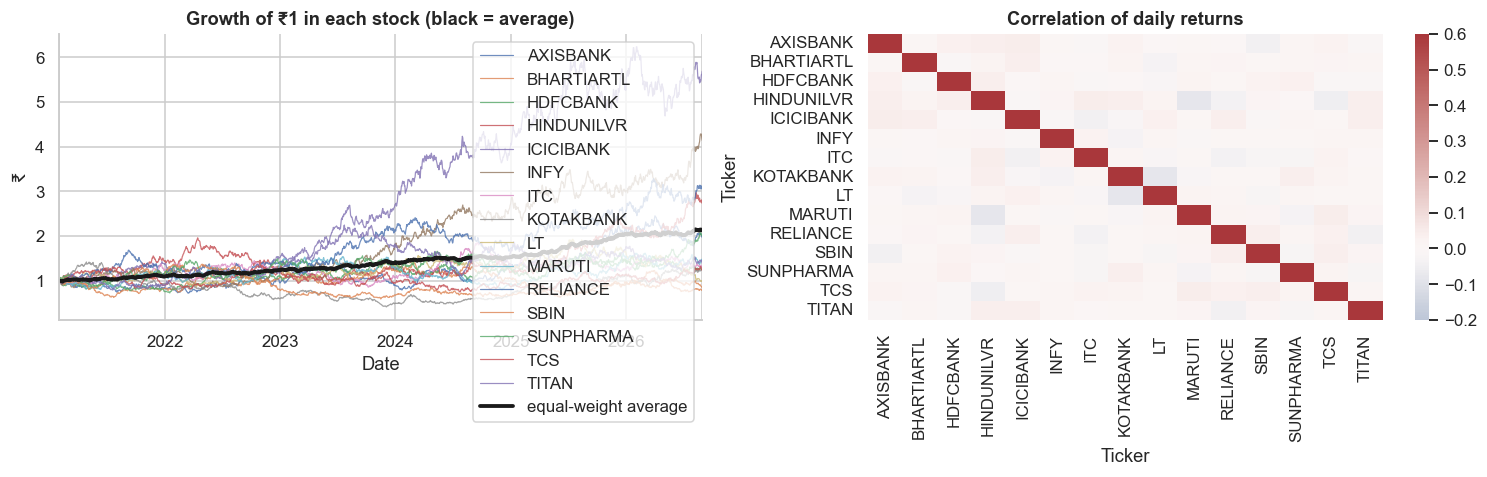

Average pairwise correlation: 0.004


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
wide = mkt.pivot(index='Date', columns='Ticker', values='Return')                     # dates x tickers
(1 + wide).cumprod().plot(ax=ax[0], legend=False, lw=0.8, alpha=0.8)                   # growth of ₹1 per stock
(1 + wide.mean(axis=1)).cumprod().plot(ax=ax[0], c='k', lw=2.5, label='equal-weight average')
ax[0].set(title='Growth of ₹1 in each stock (black = average)', ylabel='₹'); ax[0].legend()
sns.heatmap(wide.corr(), ax=ax[1], cmap='vlag', center=0, vmin=-0.2, vmax=0.6)          # how related are the stocks?
ax[1].set_title('Correlation of daily returns')
plt.tight_layout(); savefig('equity_eda'); plt.show()
print('Average pairwise correlation:', round(wide.corr().values[np.triu_indices(15, 1)].mean(), 3))

> ### 📘 Explanation — cell 11
> **Feature table.** Each feature maps to a known finance anomaly: short-term reversal (Ret_1M), momentum 6-1 (Mom_6_1), trend (Ret_3M), low-vol anomaly (Vol), CAPM beta, attention (Volume_Trend), 52-week-high effect (Dist_High_6M), intraday range, and the (noisy) macro columns.

## 2. Features known at each month-end
All computed per stock from **past** daily data (rolling windows end on the rebalance day):

| Feature | Meaning | Finance idea |
|---|---|---|
| `Ret_1M` | last 21-day return | short-term reversal |
| `Mom_6_1` | return from 6 months ago to 1 month ago | classic momentum |
| `Ret_3M` | last 63-day return | medium-term trend |
| `Vol_1M`, `Vol_3M` | daily return std over 21 / 63 days | low-volatility anomaly |
| `Beta_6M` | sensitivity to the equal-weight market (126 days) | CAPM risk |
| `Volume_Trend` | 21-day avg volume ÷ 126-day avg volume | attention / liquidity |
| `Dist_High_6M` | price ÷ 6-month high − 1 | 52-week-high effect |
| `Range_1M` | average (High − Low) ÷ Close over 21 days | intraday risk |
| `VIX`, `Interest_Rate`, `GDP_Growth` | as supplied on the rebalance day | macro (noisy here) |

> ### 📘 Explanation — cell 12
> **What it does.** Per stock, rolling computations: 21/63-day returns, **Mom 6-1** = Close(t−21)/Close(t−126) − 1
> (skips the last month to avoid the reversal effect), 63-day vol, volume ratio 21/126 days, distance to 126-day high,
> 21-day average range.
>
> **Why rolling windows ending today.** Uses only data known at the rebalance date — no look-ahead.

In [9]:
g = mkt.groupby('Ticker')                                                             # per-stock rolling windows
mkt['Ret_1M'] = g.Close.pct_change(21)                                                # last month
mkt['Ret_3M'] = g.Close.pct_change(63)                                                # last quarter
mkt['Mom_6_1'] = g.Close.shift(21) / g.Close.shift(126) - 1                           # 6 months ago to 1 month ago
mkt['Vol_1M'] = mkt.Volatility_20D                                                    # supplied 20-day volatility
mkt['Vol_3M'] = g.Return.transform(lambda r: r.rolling(63).std())                     # 63-day volatility
mkt['Volume_Trend'] = g.Volume.transform(lambda v: v.rolling(21).mean() / v.rolling(126).mean())
mkt['Dist_High_6M'] = mkt.Close / g.Close.transform(lambda c: c.rolling(126).max()) - 1
mkt['Range_1M'] = ((mkt.High - mkt.Low) / mkt.Close).groupby(mkt.Ticker).transform(lambda r: r.rolling(21).mean())

> ### 📘 Explanation — cell 13
> **What it does.** `rolling_beta` = rolling Cov(stock, market) / Var(market) over 126 days (CAPM beta); summary stats.
>
> **Output.** Beta mean 1.00 (range −0.5 to 2.1), Mom_6_1 mean 5.5%, Volume_Trend mean 1.0.

In [10]:
def rolling_beta(d, w=126):
    """Beta of one stock to the equal-weight market over the last w days."""
    return d.Return.rolling(w).cov(d.Mkt_EW) / d.Mkt_EW.rolling(w).var()

mkt['Beta_6M'] = mkt.groupby('Ticker', group_keys=False)[['Return', 'Mkt_EW']].apply(rolling_beta)   # aligned to rows
mkt[['Ret_1M', 'Mom_6_1', 'Vol_3M', 'Beta_6M', 'Volume_Trend', 'Dist_High_6M']].describe().round(3)

,Ret_1M,Mom_6_1,Vol_3M,Beta_6M,Volume_Trend,Dist_High_6M
count,21540.000,19965.000,20925.000,19980.000,19980.000,19980.000
mean,0.011,0.055,0.018,1.000,1.000,-0.114
std,0.084,0.182,0.002,0.359,0.103,0.090
min,-0.263,-0.404,0.012,-0.517,0.684,-0.446
25%,-0.045,-0.082,0.017,0.747,0.929,-0.175
50%,0.008,0.045,0.018,1.006,0.996,-0.097
75%,0.065,0.178,0.019,1.261,1.068,-0.040
max,0.433,0.882,0.024,2.086,1.447,0.000


> ### 📘 Explanation — cell 14
> **Section header** – monthly panel and target.

## 3. Monthly panel and target

> ### 📘 Explanation — cell 15
> **What it does.** Keeps only the last trading day of each month; `Fwd_Ret` = next month-end close / this close − 1;
> `Fwd_Excess` = Fwd_Ret − cross-sectional mean that month.
>
> **Output.** 68 month-ends × 15 = 1,020 rows.
>
> **Why shift(−1).** The target is the *future* return; features are at month-end t, the target covers t → t+1.

In [11]:
month_ends = mkt.groupby(mkt.Date.dt.to_period('M')).Date.max()                         # last trading day of each month
panel = mkt[mkt.Date.isin(month_ends)].copy()                                          # one row per stock per month-end
panel = panel.sort_values(['Ticker', 'Date']).reset_index(drop=True)
panel['Fwd_Ret'] = panel.groupby('Ticker').Close.shift(-1) / panel.Close - 1            # return over the NEXT month
panel['Fwd_Excess'] = panel.Fwd_Ret - panel.groupby('Date').Fwd_Ret.transform('mean')   # vs average of the 15 stocks
print('month-ends:', panel.Date.nunique(), '| rows:', len(panel))

month-ends: 68 | rows: 1020


> ### 📘 Explanation — cell 16
> **What it does.** Drops rows where rolling windows are incomplete (first ~6 months).
>
> **Output.** 62 usable month-ends (2021-07 → 2026-08); the last month has no outcome yet — it is the **live forecast**.

In [12]:
FEATURES = ['Ret_1M', 'Ret_3M', 'Mom_6_1', 'Vol_1M', 'Vol_3M', 'Beta_6M', 'Volume_Trend', 'Dist_High_6M', 'Range_1M',
            'VIX', 'Interest_Rate', 'GDP_Growth']
data = panel.dropna(subset=FEATURES).copy()                     # drop the first 6 months (rolling windows not full yet)
dates = sorted(data.Date.unique())                              # rebalance dates in order
print('usable month-ends:', len(dates), '|', pd.Timestamp(dates[0]).date(), 'to', pd.Timestamp(dates[-1]).date())
print('last month-end has no next-month return (it is the live forecast):', int(data.Fwd_Ret.isna().sum()), 'rows')

usable month-ends: 62 | 2021-07-30 to 2026-08-31
last month-end has no next-month return (it is the live forecast): 15 rows


> ### 📘 Explanation — cell 17
> **What it does.** For each feature, average monthly **Spearman rank IC** with next-month excess return (full sample, descriptive).
>
> **Output.** All between −0.06 (Volume_Trend) and +0.04 (Interest_Rate).
>
> **How to read.** No single feature has a strong IC → warning before any model is fitted. (Descriptive only: uses the full sample.)

In [13]:
# Quick look: one-variable rank IC of each feature with next-month excess return (full sample, descriptive only)
lab = data.dropna(subset=['Fwd_Excess'])
ic1 = {f: lab.groupby('Date').apply(lambda d: stats.spearmanr(d[f], d.Fwd_Excess)[0]).mean() for f in FEATURES}
pd.Series(ic1, name='mean monthly rank IC').sort_values().round(4)

Volume_Trend    -0.0618
GDP_Growth      -0.0452
Mom_6_1         -0.0403
Dist_High_6M    -0.0270
Range_1M        -0.0191
Ret_1M          -0.0107
Ret_3M          -0.0058
Vol_1M           0.0044
Beta_6M          0.0278
Vol_3M           0.0348
VIX              0.0398
Interest_Rate    0.0443
Name: mean monthly rank IC, dtype: float64

> ### 📘 Explanation — cell 18
> **Rank IC explained.** Spearman correlation across the 15 stocks in one month between signal and next return. 0.03–0.05 average IC is already useful in practice; 0 = no skill. IC is the right metric because only the *ranking* is traded.

**Rank IC** (information coefficient) is the rank correlation, across the 15 stocks in one month, between a signal
and the next-month return. In practice an average IC of 0.03–0.05 is already useful; 0 means no skill.
Every single feature here sits close to zero, which is a warning before any model is fitted.

> ### 📘 Explanation — cell 19
> **Walk-forward design.** For each month t after the first 24: fit on all earlier months (outcomes known by t), predict month t, step forward, refit (expanding window). Benchmarks: Momentum (no ML) and zero forecast (= equal-weight).

## 4. Walk-forward forecasting (Task 1)
For each rebalance month *t* (after the first 24): fit each model on all months **before** *t* (their next-month
returns are fully known by *t*), predict the excess return for month *t*'s 15 stocks, move one month forward, refit.

Models: **Ridge** (linear, shrinks coefficients so noise cannot dominate), **Random forest**, **Gradient boosting**
(both kept small). Benchmarks: **Momentum** (rank by `Mom_6_1`, no ML) and **zero forecast** (no view; the
equal-weight portfolio).

> ### 📘 Explanation — cell 20
> **What it does.** Ridge (α = 50, strong shrinkage), RF (300 trees, min leaf 20, 50% features), GB (depth 2, lr 0.03, 150 iterations, min leaf 20).
>
> **Why kept small.** Monthly stock returns are mostly noise; ~600–900 training rows; small/regularised models reduce overfitting.

In [14]:
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=50.0)),
    'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
    'Gradient boosting': HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=150, min_samples_leaf=20, random_state=SEED),
}

> ### 📘 Explanation — cell 21
> **What it does.** The walk-forward loop: for each forecast month, train on all earlier labelled months, predict the 15
> stocks with each model; momentum benchmark = Mom_6_1 minus its cross-sectional mean.
>
> **Output.** **38 forecast months**, 2023-07 → 2026-08.
>
> **Why this is the right validation.** Every prediction is genuinely out-of-sample *in time* — the strongest possible
> protection against look-ahead bias in financial ML.

In [15]:
preds = []                                                              # one block of predictions per test month
for i in range(MIN_TRAIN_MONTHS, len(dates)):
    t = dates[i]                                                        # rebalance date we forecast from
    tr = data[(data.Date < t)].dropna(subset=['Fwd_Excess'])            # all earlier months with known outcomes
    te = data[data.Date == t].copy()                                    # the 15 stocks at date t
    for name, m in models.items():
        te[f'Pred_{name}'] = m.fit(tr[FEATURES], tr.Fwd_Excess).predict(te[FEATURES])   # refit and forecast
    te['Pred_Momentum'] = te.Mom_6_1 - te.Mom_6_1.mean()               # naive benchmark: past winners keep winning
    preds.append(te)
pred = pd.concat(preds, ignore_index=True)
PRED_COLS = [f'Pred_{n}' for n in models] + ['Pred_Momentum']
print('forecast months:', pred.Date.nunique(), '|', pred.Date.min().date(), 'to', pred.Date.max().date())

forecast months: 38 | 2023-07-31 to 2026-08-31


> ### 📘 Explanation — cell 22
> **Section header** – forecast quality, out of sample only.

## 5. Forecast quality, out of sample only

> ### 📘 Explanation — cell 23
> **What it does.** For each forecast: mean monthly rank IC, **IC t-stat** = mean/std × √n, share of months IC > 0,
> **hit rate** (sign of forecast = sign of excess return), and **OOS R² vs zero** = 1 − SSE/Σ(actual²).
>
> **Output.**
> | Model | IC | t | IC>0 | hit | R² |
> |---|---|---|---|---|---|
> | Ridge | **0.056** | 1.23 | 57% | 52% | 0.001 |
> | RF | 0.004 | 0.09 | 57% | 52% | −0.021 |
> | GB | 0.014 | 0.35 | 43% | 52% | −0.020 |
> | Momentum | −0.024 | −0.49 | 49% | 49% | (n/a) |
>
> **How to read.** Ridge's IC looks economically interesting but t = 1.2 < 2 over 38 months ⇒ could be luck. R² ≈ 0 is
> normal for stock returns. Momentum's R² is not comparable (it is a ranking, not a return forecast).

In [16]:
ev = pred.dropna(subset=['Fwd_Excess'])                                 # months whose outcome we know
rows = {}
for c in PRED_COLS:
    ic = ev.groupby('Date').apply(lambda d: stats.spearmanr(d[c], d.Fwd_Excess)[0])      # monthly rank IC
    hit = (np.sign(ev[c]) == np.sign(ev.Fwd_Excess)).mean()                             # right side of average?
    r2 = 1 - ((ev.Fwd_Excess - ev[c]) ** 2).sum() / (ev.Fwd_Excess ** 2).sum()          # R² vs forecasting zero
    rows[c.replace('Pred_', '')] = {'mean IC': ic.mean(), 'IC t-stat': ic.mean() / ic.std() * np.sqrt(len(ic)),
                                    'months IC > 0': (ic > 0).mean(), 'hit rate': hit, 'OOS R² vs zero': r2}
quality = pd.DataFrame(rows).T
quality.round(4)

,mean IC,IC t-stat,months IC > 0,hit rate,OOS R² vs zero
Ridge,0.0564,1.2332,0.5676,0.5207,0.0011
Random forest,0.0039,0.0913,0.5676,0.5207,-0.0208
Gradient boosting,0.0143,0.3490,0.4324,0.5225,-0.0199
Momentum,-0.0242,-0.4914,0.4865,0.4919,-4.4308


> ### 📘 Explanation — cell 24
> **What it does.** Comparison table vs a "zero forecast" (IC 0, hit 50%), Ridge marked chosen.
>
> **Output.** Ridge +0.056 IC over no view; GB 0.042 behind; momentum −0.024.
>
> **Why Ridge wins here.** Linear shrinkage is the best tool when signal-to-noise is very low — trees chase noise.

In [17]:
# Comparison table: rank IC gained by each model over a "no view" forecast (IC = 0)
q = quality.copy()
q.loc['Zero forecast (no view)'] = [0.0, 0.0, 0.5, 0.5, 0.0]                  # no skill by construction
compare_models(q, 'mean IC', chosen='Ridge', baseline='Zero forecast (no view)',
               extra=['IC t-stat', 'months IC > 0', 'hit rate']).round(4)

,Rank,mean IC,IC t-stat,months IC > 0,hit rate,Gain vs baseline,Gap to best,Chosen
Ridge,1,0.0564,1.2332,0.5676,0.5207,0.0564,0.0000,✔
Gradient boosting,2,0.0143,0.3490,0.4324,0.5225,0.0143,0.0421,
Random forest,3,0.0039,0.0913,0.5676,0.5207,0.0039,0.0525,
Zero forecast (no view),4,0.0000,0.0000,0.5000,0.5000,0.0000,0.0564,
Momentum,5,-0.0242,-0.4914,0.4865,0.4919,-0.0242,0.0806,


> ### 📘 Explanation — cell 25
> **Reading guide.** t > 2 needed for a real edge; OOS R² < 0 = worse than forecasting zero; judge momentum by IC only. **Result:** Ridge best but not statistically reliable; trees ≈ no skill.

**How to read this.** A t-stat above about 2 would suggest a real edge. Out-of-sample R² below 0 means the model's
return forecasts are *worse* than simply forecasting "no excess return", which is common for stock returns, where
noise dominates. The useful number for stock **selection** is the IC, because only the ranking is traded.

*Note on Momentum's R².* The momentum "forecast" is the stock's past 6-month return minus the average. It is a
**ranking** signal, not a forecast of next month's return in the same units, so its R² (very negative) is not
comparable. Judge momentum by its IC only.

**Result.** Ridge has the best IC (≈ 0.06) and is positive in 57% of months, but its t-stat (≈ 1.2) is well below 2,
so the edge is **not statistically reliable** over 38 months. The tree models have essentially no skill and momentum
is slightly negative.

> ### 📘 Explanation — cell 26
> **Portfolio test design.** Each month: rank by forecast, hold top 5 equally for one month, charge 10 bps on traded value; compare with holding all 15 equally.

## 6. Rank, select and build a simple portfolio (Task 2)
At each month-end: rank the 15 stocks by each forecast, hold the **top 5 equally weighted** for one month,
charge 10 bps on the value traded. Compare with holding **all 15 equally** (no forecast).

> ### 📘 Explanation — cell 27
> **What it does.** `top_n_portfolio()` computes monthly gross return of the top 5, **turnover** (share of names replaced),
> and net return = gross − 2 × cost × turnover (sell + buy). `perf()` computes annualised return (compound), vol (×√12),
> Sharpe (excess over 7%/12), max drawdown (from running peak).
>
> **Why these metrics.** Sharpe = risk-adjusted return; drawdown = worst peak-to-trough loss (what investors feel).

In [18]:
def top_n_portfolio(df, col, n=TOP_N, tc=TC):
    """Monthly returns of an equal-weight top-n portfolio, after costs on the names that change."""
    out, prev = [], set()
    for d, grp in df.groupby('Date'):
        pick = set(grp.nlargest(n, col).Ticker)                       # stocks held this month
        gross = grp[grp.Ticker.isin(pick)].Fwd_Ret.mean()             # equal-weight return of the picks
        turnover = 1.0 if not prev else len(pick - prev) / n          # share of the portfolio replaced
        out.append({'Date': d, 'gross': gross, 'turnover': turnover, 'net': gross - 2 * tc * turnover})   # sell + buy
        prev = pick
    return pd.DataFrame(out).set_index('Date')

def perf(r, periods=12):
    """Annualised return, volatility, Sharpe and max drawdown of a monthly return series."""
    ann_ret = (1 + r).prod() ** (periods / len(r)) - 1                 # compound annual growth
    ann_vol = r.std() * np.sqrt(periods)
    sharpe = (r.mean() - RF_ANNUAL / periods) / r.std() * np.sqrt(periods)
    wealth = (1 + r).cumprod(); dd = (wealth / wealth.cummax() - 1).min()
    return {'Ann. return': ann_ret, 'Ann. vol': ann_vol, 'Sharpe': sharpe, 'Max drawdown': dd}

> ### 📘 Explanation — cell 28
> **What it does.** Backtests EW-all-15 and top-5 portfolios for each forecast.
>
> **Output.**
> | Portfolio | Return | Vol | Sharpe | MaxDD | Turnover |
> |---|---|---|---|---|---|
> | **EW all 15** | 16.2% | **6.3%** | **1.32** | −2.4% | 0 |
> | Top 5 Ridge | 17.2% | 13.7% | 0.72 | −9.5% | 68% |
> | Top 5 GB | **20.4%** | 12.1% | 1.03 | −8.2% | 68% |
> | Top 5 RF | 9.7% | 13.0% | 0.24 | −12.1% | 64% |
> | Top 5 Momentum | 11.3% | 13.6% | 0.34 | −15.0% | 35% |
>
> **How to read.** Concentrating in 5 stocks doubles volatility (losing diversification), so even higher raw returns give
> lower Sharpe.

In [19]:
ev_months = ev.copy()                                                    # months with known outcomes
ew = ev_months.groupby('Date').Fwd_Ret.mean()                            # equal-weight all 15 (benchmark)
ports = {'Equal-weight (all 15)': ew}
turn = {'Equal-weight (all 15)': 0.0}
for c in PRED_COLS:
    p = top_n_portfolio(ev_months, c)
    ports[f'Top {TOP_N}: {c.replace("Pred_", "")}'] = p.net
    turn[f'Top {TOP_N}: {c.replace("Pred_", "")}'] = p.turnover.iloc[1:].mean()
port_tbl = pd.DataFrame({k: perf(v) for k, v in ports.items()}).T
port_tbl['Avg monthly turnover'] = pd.Series(turn)
port_tbl.round(4)

,Ann. return,Ann. vol,Sharpe,Max drawdown,Avg monthly turnover
Equal-weight (all 15),0.1618,0.0627,1.3211,-0.0242,0.0000
Top 5: Ridge,0.1717,0.1367,0.7206,-0.0950,0.6778
Top 5: Random forest,0.0974,0.1298,0.2429,-0.1214,0.6389
Top 5: Gradient boosting,0.2035,0.1207,1.0253,-0.0821,0.6778
Top 5: Momentum,0.1133,0.1359,0.3442,-0.1495,0.3500


> ### 📘 Explanation — cell 29
> **What it does.** Ranks portfolios by Sharpe with EW as the baseline.
>
> **Output.** EW ranks 1st; GB top-5 is −0.30 Sharpe behind; RF −1.08.

In [20]:
# Comparison table on risk-adjusted return: what does each strategy gain over simply holding all 15?
compare_models(port_tbl, 'Sharpe', chosen='Equal-weight (all 15)', baseline='Equal-weight (all 15)',
               extra=['Ann. return', 'Ann. vol', 'Max drawdown', 'Avg monthly turnover']).round(4)

,Rank,Sharpe,Ann. return,Ann. vol,Max drawdown,Avg monthly turnover,Gain vs baseline,Gap to best,Chosen
Equal-weight (all 15),1,1.3211,0.1618,0.0627,-0.0242,0.0000,0.0000,0.0000,✔
Top 5: Gradient boosting,2,1.0253,0.2035,0.1207,-0.0821,0.6778,-0.2959,0.2959,
Top 5: Ridge,3,0.7206,0.1717,0.1367,-0.0950,0.6778,-0.6005,0.6005,
Top 5: Momentum,4,0.3442,0.1133,0.1359,-0.1495,0.3500,-0.9769,0.9769,
Top 5: Random forest,5,0.2429,0.0974,0.1298,-0.1214,0.6389,-1.0782,1.0782,


> ### 📘 Explanation — cell 30
> **What it does.** **Paired t-test** (one-sample t on monthly return differences vs EW) for each top-5 portfolio.
>
> **Why paired.** Both portfolios face the same months → differencing removes common market noise.
>
> **Output.** Ridge +0.13%/month, t = 0.24, p = 0.81; GB +0.34%, t = 0.71, p = 0.48; RF and momentum negative.
>
> **How to read.** All p > 0.4 ⇒ no top-5 strategy beats EW significantly.

In [21]:
# Is any top-5 portfolio significantly better than equal-weight? Paired t-test on monthly return differences.
sig = {}
for k, v in ports.items():
    if k.startswith('Equal'): continue
    diff = v - ew                                                       # monthly out-/under-performance
    sig[k] = {'mean monthly excess': diff.mean(), 't-stat': stats.ttest_1samp(diff, 0).statistic,
              'p-value': stats.ttest_1samp(diff, 0).pvalue}
pd.DataFrame(sig).T.round(4)

,mean monthly excess,t-stat,p-value
Top 5: Ridge,0.0013,0.2413,0.8107
Top 5: Random forest,-0.0043,-0.8242,0.4153
Top 5: Gradient boosting,0.0034,0.7145,0.4796
Top 5: Momentum,-0.0030,-0.5968,0.5544


> ### 📘 Explanation — cell 31
> **Interpretation.** EW wins on Sharpe because the synthetic stocks are nearly uncorrelated; top-5 portfolios give up diversification and turn over 2/3 of names monthly. **Implication:** don't concentrate; notebook 06 tests ML as a *tilt* on a diversified portfolio.

**Reading the portfolio table.**
- Equal-weight across all 15 stocks has the **best Sharpe ratio**. These 15 synthetic stocks are almost uncorrelated
  (average correlation 0.004; real Indian large caps are closer to 0.3–0.4), so holding all 15 cancels most of the
  risk. A 5-stock portfolio gives up that diversification and roughly doubles volatility.
- Some top-5 portfolios earn a higher raw return (gradient boosting ~20% a year), but none beats equal-weight
  **significantly** (all p-values > 0.4), and their Sharpe ratios are lower.
- The ML portfolios replace about two thirds of their names every month, so costs and market impact matter.

**Implication.** Concentrating on ML picks is not justified. Notebook 06 tests the better use of a weak signal:
a **tilt** of a diversified portfolio towards the ML favourites, compared with equal-weight and Markowitz.

> ### 📘 Explanation — cell 32
> **What it does.** Growth of ₹1 (after costs) for all portfolios, and Ridge's monthly IC bars (green > 0, red < 0) with the mean. Saves `equity_backtest.png`.
>
> **How to read.** IC bars swing widely around a small positive mean — visual evidence of a weak, noisy signal.

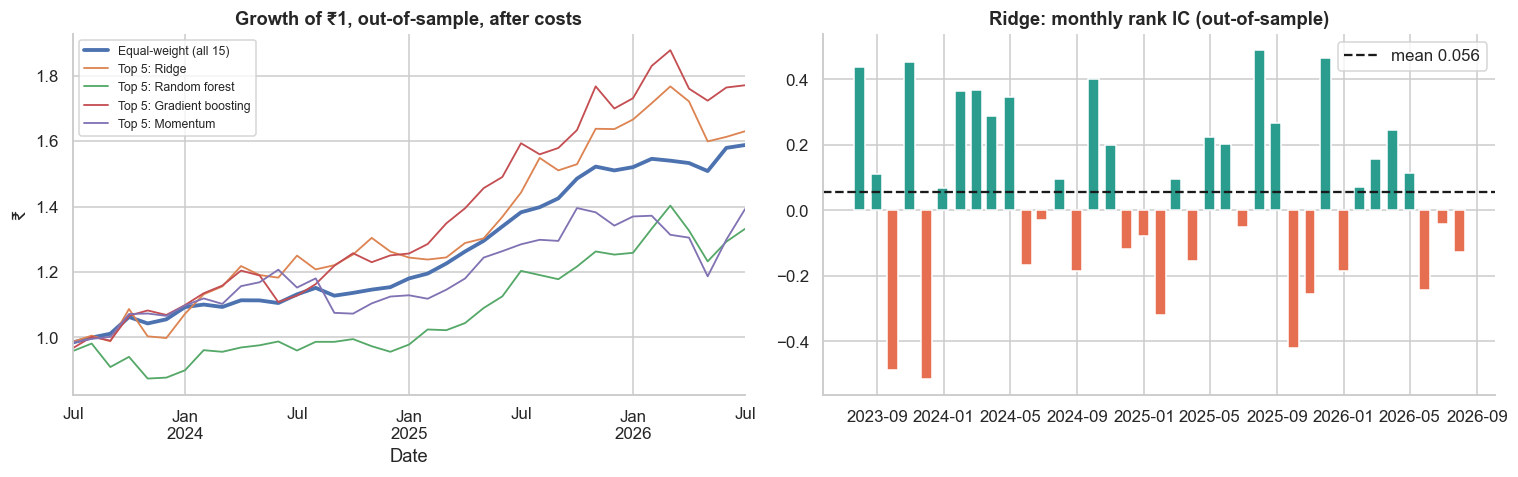

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, v in ports.items():
    (1 + v).cumprod().plot(ax=ax[0], label=k, lw=2.5 if k.startswith('Equal') else 1.2)
ax[0].set(title='Growth of ₹1, out-of-sample, after costs', ylabel='₹'); ax[0].legend(fontsize=8)
ics = ev.groupby('Date').apply(lambda d: stats.spearmanr(d['Pred_Ridge'], d.Fwd_Excess)[0])
ax[1].bar(ics.index, ics.values, width=20, color=np.where(ics > 0, '#2a9d8f', '#e76f51'))
ax[1].axhline(ics.mean(), c='k', ls='--', label=f'mean {ics.mean():.3f}')
ax[1].set(title='Ridge: monthly rank IC (out-of-sample)'); ax[1].legend()
plt.tight_layout(); savefig('equity_backtest'); plt.show()

> ### 📘 Explanation — cell 33
> **Explainability.** Ridge is linear → standardised coefficients are its explanation (sign = direction). Fitted on all labelled months for this view only (not used for backtesting).

## 7. What does the model use? (explainability)
Ridge is linear, so its standardised coefficients are its explanation: a positive coefficient means a higher value
of that feature predicts a higher next-month excess return. We fit on all labelled months for this view only.

> ### 📘 Explanation — cell 34
> **What it does.** Fits Ridge on the full labelled sample and lists coefficients per 1 std, sorted by size.
>
> **Output.** Volume_Trend −0.0054, Mom_6_1 −0.0050, Ret_3M −0.0048, Dist_High_6M **+0.0047**, GDP −0.0036 …
>
> **How to read.** Tiny coefficients (≈ 0.5% monthly excess per 1 std): recent volume surges and strong past returns
> predict slightly *lower* next-month returns (mild **reversal**); being near the 6-month high predicts slightly higher.

In [23]:
final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=50.0)).fit(lab[FEATURES], lab.Fwd_Excess)   # full-sample fit
coef = pd.Series(final_ridge[-1].coef_, index=FEATURES).sort_values(key=np.abs, ascending=False)        # sorted by size
coef.round(5).to_frame('Ridge coefficient (per 1 std)')

,Ridge coefficient (per 1 std)
Volume_Trend,-0.00543
Mom_6_1,-0.00502
Ret_3M,-0.00482
Dist_High_6M,0.00474
GDP_Growth,-0.00364
Ret_1M,-0.00340
Range_1M,-0.00231
VIX,0.00224
Beta_6M,0.00223
Vol_3M,0.00194


> ### 📘 Explanation — cell 35
> **What it does.** Fits GB on full data and draws TreeExplainer SHAP beeswarm (`equity_shap.png`) — a second, non-linear view of the drivers to compare with Ridge's coefficients.

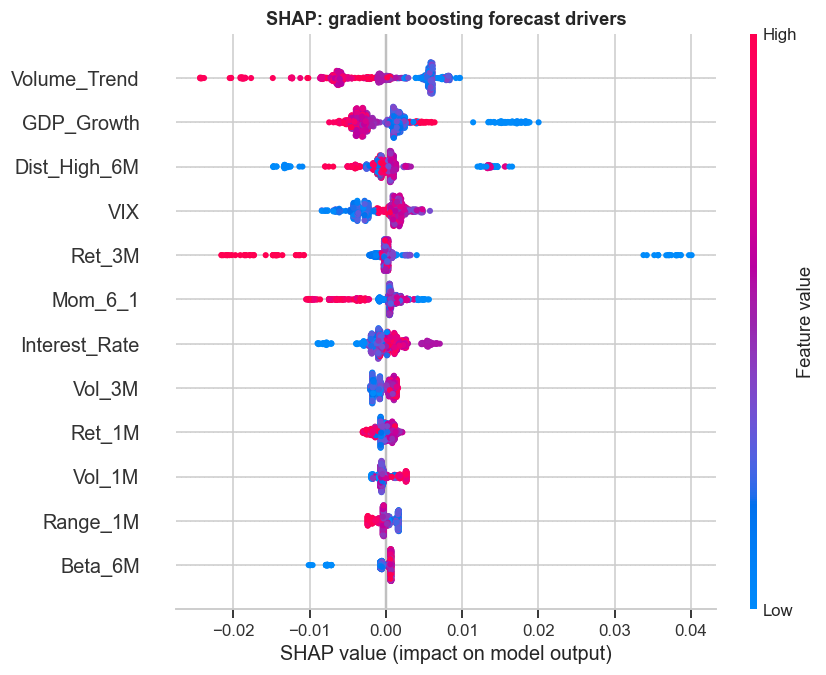

In [24]:
import shap                                                                 # tree-model explanation
gb_full = HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=150, min_samples_leaf=20,
                                        random_state=SEED).fit(lab[FEATURES], lab.Fwd_Excess)
sv = shap.TreeExplainer(gb_full)(lab[FEATURES])                             # exact SHAP for the tree model
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title('SHAP: gradient boosting forecast drivers'); plt.tight_layout(); savefig('equity_shap'); plt.show()

> ### 📘 Explanation — cell 36
> **Section header** – live ranking and hand-off.

## 8. Live ranking (latest month-end) and hand-off to notebook 06

> ### 📘 Explanation — cell 37
> **What it does.** Shows the latest month-end forecasts ranked by Ridge.
>
> **Output.** Top 5 by Ridge: TITAN, LT, HDFCBANK, ICICIBANK, TCS. Models disagree (e.g. LT: GB +6%, momentum −16%).
>
> **How to read.** This is the forward-looking signal notebook 06 can use for the tilt; the disagreement is another sign of a weak signal.

In [25]:
live = pred[pred.Date == pred.Date.max()].sort_values('Pred_Ridge', ascending=False)        # most recent forecast
live['Rank'] = np.arange(1, len(live) + 1)                                                  # 1 = most attractive
live[['Rank', 'Ticker', 'Sector'] + PRED_COLS].round(4)

,Rank,Ticker,Sector,Pred_Ridge,Pred_Random forest,Pred_Gradient boosting,Pred_Momentum
569,1,TITAN,Consumer,0.0118,0.0109,0.0090,0.0129
563,2,LT,Industrials,0.0112,0.0334,0.0606,-0.1616
557,3,HDFCBANK,Banking,0.0105,0.0246,0.0183,-0.0807
559,4,ICICIBANK,Banking,0.0063,0.0184,0.0091,0.0198
568,5,TCS,IT,0.0054,0.0092,0.0108,0.0805
555,6,AXISBANK,Banking,0.0045,-0.0036,0.0031,-0.2103
561,7,ITC,Consumer,0.0021,-0.0065,-0.0138,-0.1090
556,8,BHARTIARTL,Telecom,0.0015,0.0002,0.0077,-0.2053
564,9,MARUTI,Auto,-0.0015,0.0128,-0.0016,-0.0626
565,10,RELIANCE,Energy,-0.0028,-0.0098,-0.0048,-0.0180


> ### 📘 Explanation — cell 38
> **What it does.** Saves all walk-forward predictions, features and outcomes to `equity_predictions.csv` (570 rows × 22) for notebook 06.

In [26]:
out_cols = ['Date', 'Ticker', 'Sector', 'Close', 'Fwd_Ret', 'Fwd_Excess'] + FEATURES + PRED_COLS
pred[out_cols].to_csv(RES / 'equity_predictions.csv', index=False)                      # notebook 06 reads this
print('saved results/equity_predictions.csv', pred[out_cols].shape)

saved results/equity_predictions.csv (570, 22)


> ### 📘 Explanation — cell 39
> **What it does.** Saves `equity.json`: design assumptions, number of forecast months, quality table, portfolio table, significance tests, per-stock stats.

In [27]:
res = {'module': 'equity',
       'assumptions': {'rebalance': 'monthly', 'target': 'next-month return minus 15-stock average',
                       'min_train_months': MIN_TRAIN_MONTHS, 'top_n': TOP_N, 'tc_per_unit_traded': TC},
       'forecast_months': int(ev.Date.nunique()),
       'quality': quality.round(4).to_dict(orient='index'),
       'portfolios': port_tbl.round(4).to_dict(orient='index'),
       'significance_vs_equal_weight': pd.DataFrame(sig).T.round(4).to_dict(orient='index'),
       'stock_stats': summary.round(4).to_dict(orient='index')}
save_result('equity', res)

saved results/Module_05_Equity_Returns/equity.json


> ### 📘 Explanation — cell 40
> **Headline results & limitations** – Ridge IC 0.056 (t 1.2), OOS R² ≈ 0 → ML does not reliably pick winners; EW Sharpe 1.32 best; diversify first. Limitations: only 15 stocks and 38 months (low power), noisy macro columns, survivorship bias, flat 10 bps costs.

## Headline results
- **Data.** Clean 15-stock daily panel (Jan 2021 – Aug 2026). The supplied return/momentum/volatility columns are
  correct and free of look-ahead. The "macro" columns differ by stock on the same day, so they are not real macro
  signals. The stocks are almost uncorrelated (0.004), which makes diversification unusually powerful here.
- **Forecasting (38 out-of-sample months, walk-forward, monthly refits).** Ridge has the best rank IC, 0.056
  (t = 1.2, positive in 57% of months). Random forest 0.004, gradient boosting 0.014, momentum −0.024.
  Out-of-sample R² ≈ 0 for all ML models. **ML does not reliably identify the stocks with superior returns.**
- **Stock selection (top 5, equal-weight, 10 bps costs).** Gradient boosting top-5: 20.4% a year, Sharpe 1.03.
  Ridge top-5: 17.2%, Sharpe 0.72. Equal-weight all 15: 16.2%, vol 6.3%, **Sharpe 1.32**. No top-5 portfolio beats
  equal-weight significantly (p > 0.4). Turnover is about 68% a month.
- **Drivers.** Small, mixed effects: recent volume surges and strong past returns predict slightly *lower*
  next-month excess return (a mild reversal). Being near the 6-month high predicts slightly higher.
- **For notebooks 06 and 10.** The equity sleeve should be **diversified first** (equal-weight or risk-based), with ML
  used at most as a small tilt. The expected return and risk of the equity line come from notebook 06's backtest.

## Risks and limitations
- Only 15 stocks and about 3 years of out-of-sample months: even a real edge would be hard to prove statistically.
- Macro columns vary by stock on the same day, so they cannot be used as genuine macro signals.
- Survivorship: the 15 names are today's large caps; a real backtest needs the historical index membership.
- Costs are a flat 10 bps; market impact on large orders would be higher.